# 02 – Modèle de prévision J+1 et comparaison avec Elia

**Question** : la veille à midi, peut-on prévoir la consommation belge heure par heure du lendemain,
et à quel point s'approche-t-on de la prévision officielle d'Elia ?

**Règle d'honnêteté** : sur la période de test, le modèle n'utilise que ce qui est connu la veille,
donc la **prévision** météo de la veille, pas la météo réelle.

In [1]:
import sys
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

sys.path.append("../src")
from features import build_dataset, FEATURES, TARGET

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True

## 1. Données

- `obs` : variables construites avec la météo **observée** (pour l'entraînement).
- `fc` : variables construites avec la météo **prévue la veille** (pour le test).

In [2]:
obs = build_dataset("observed")
fc = build_dataset("forecast_d1")
obs[FEATURES + [TARGET, "elia_dayahead_mw"]].tail(3)

,hour,dayofweek,dayofyear,is_holiday,temperature_c,temperature_24h,heating_degrees,radiation_wm2,load_lag_48h,load_lag_168h,load_mw,elia_dayahead_mw
datetime_utc,,,,,,,,,,,,
2026-11-12 20:00:00+00:00,21,3,316,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9832.9925
2026-11-12 21:00:00+00:00,22,3,316,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9543.9050
2026-11-12 22:00:00+00:00,23,3,316,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9246.0275


## 2. Découpage dans le temps

On ne mélange jamais passé et futur : on entraîne sur le passé, on teste sur la suite.

- **Entraînement** : 2016 à 2023, sans le premier confinement (mi-mars à fin juin 2020), période trop atypique.
- **Test** : du 21 janvier 2024 à aujourd'hui, la période où la prévision météo de la veille existe.

In [3]:
train = obs.loc["2016":"2023"].drop(obs.loc["2020-03-15":"2020-06-30"].index)
train = train.dropna(subset=FEATURES + [TARGET])

test = fc.loc["2024-01-21":].dropna(subset=FEATURES + [TARGET, "elia_dayahead_mw"])
test_obs = obs.loc[test.index]   # mêmes heures, mais avec la météo réelle (pour comparaison)

print(f"Entraînement : {len(train):,} heures, de {train.index.min():%Y-%m-%d} à {train.index.max():%Y-%m-%d}")
print(f"Test         : {len(test):,} heures, de {test.index.min():%Y-%m-%d} à {test.index.max():%Y-%m-%d}")

Entraînement : 67,533 heures, de 2016-01-01 à 2023-12-31
Test         : 24,456 heures, de 2024-01-21 à 2026-11-04


## 3. Modèle : gradient boosting

Un ensemble d'arbres de décision construits les uns après les autres, chacun corrigeant les erreurs du précédent.
Il capte bien les effets non linéaires (le chauffage ne démarre que sous ~15 °C) et les interactions
(l'effet de l'heure n'est pas le même un dimanche et un mardi).

In [4]:
model = HistGradientBoostingRegressor(
    max_iter=500, learning_rate=0.05, categorical_features=["dayofweek"], random_state=0
)
model.fit(train[FEATURES], train[TARGET])

,loss,'squared_error'
,quantile,None
,learning_rate,0.05
,max_iter,500
,max_leaf_nodes,31
,max_depth,None
,min_samples_leaf,20
,l2_regularization,0.0
,max_features,1.0
,max_bins,255
,categorical_features,['dayofweek']


## 4. Évaluation sur 2024-2026

On compare quatre prévisions :
1. **Naïve** : la même heure 7 jours plus tôt. Le minimum à battre.
2. **Notre modèle, météo prévue** : la situation réelle, comparable à Elia.
3. **Notre modèle, météo réelle** : impossible en pratique, montre ce que coûte l'erreur de la météo.
4. **Elia** : la prévision J+1 officielle.

In [5]:
preds = pd.DataFrame({
    "Naïve (J-7)": test["load_lag_168h"],
    "Modèle (météo prévue)": model.predict(test[FEATURES]),
    "Modèle (météo réelle)": model.predict(test_obs[FEATURES]),
    "Elia J+1": test["elia_dayahead_mw"],
}, index=test.index)
y = test[TARGET]

def scores(p):
    err = (y - p).abs()
    return pd.Series({"MAE (MW)": err.mean(), "MAPE (%)": 100 * (err / y).mean()})

results = preds.apply(scores).T.round(1)
results

,MAE (MW),MAPE (%)
Naïve (J-7),428.4,4.6
Modèle (météo prévue),259.3,2.8
Modèle (météo réelle),252.7,2.8
Elia J+1,255.7,2.8


## 5. Erreur par heure de la journée

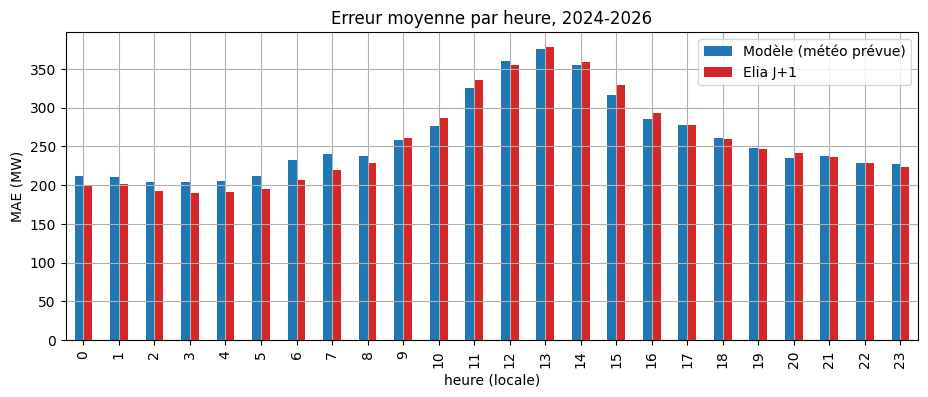

In [6]:
local_hour = test.index.tz_convert("Europe/Brussels").hour
mae_by_hour = preds[["Modèle (météo prévue)", "Elia J+1"]].sub(y, axis=0).abs().groupby(local_hour).mean()
ax = mae_by_hour.plot(kind="bar", color=["tab:blue", "tab:red"])
ax.set_xlabel("heure (locale)"); ax.set_ylabel("MAE (MW)"); ax.set_title("Erreur moyenne par heure, 2024-2026")
plt.show()

## 6. Erreur par mois

C:\Users\marwa\AppData\Local\Temp\ipykernel_48388\3544496832.py:1: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  month = test.index.tz_convert("Europe/Brussels").to_period("M")


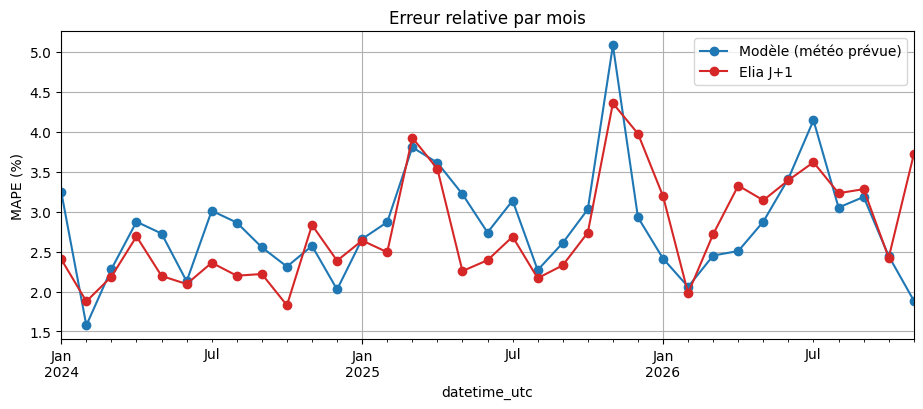

In [7]:
month = test.index.tz_convert("Europe/Brussels").to_period("M")
mape_by_month = preds[["Modèle (météo prévue)", "Elia J+1"]].sub(y, axis=0).abs().div(y, axis=0).groupby(month).mean() * 100
ax = mape_by_month.plot(color=["tab:blue", "tab:red"], marker="o")
ax.set_ylabel("MAPE (%)"); ax.set_title("Erreur relative par mois")
plt.show()

## 7. Une semaine type : prévisions et réalité

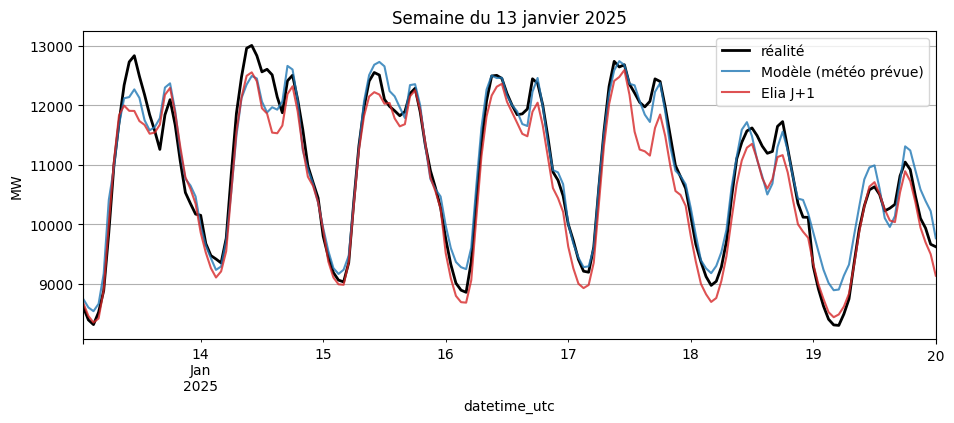

In [8]:
week = slice("2025-01-13", "2025-01-19")
ax = y.loc[week].tz_convert("Europe/Brussels").plot(color="black", lw=2, label="réalité")
for name, color in [("Modèle (météo prévue)", "tab:blue"), ("Elia J+1", "tab:red")]:
    preds[name].loc[week].tz_convert("Europe/Brussels").plot(ax=ax, color=color, alpha=0.8, label=name)
ax.set_ylabel("MW"); ax.legend(); ax.set_title("Semaine du 13 janvier 2025")
plt.show()

## 8. Quelles variables comptent ?

Importance par permutation : on mélange une variable au hasard et on mesure de combien l'erreur augmente.
Plus elle augmente, plus le modèle dépend de cette variable.

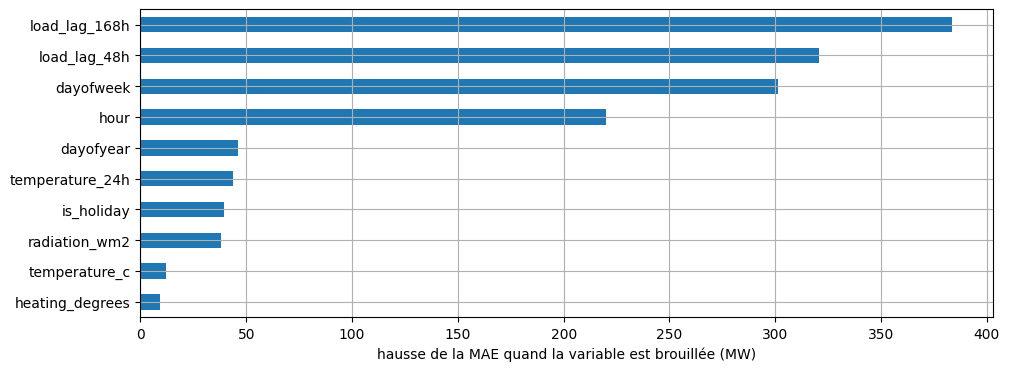

In [9]:
sample = test.sample(5000, random_state=0)
imp = permutation_importance(model, sample[FEATURES], sample[TARGET],
                             scoring="neg_mean_absolute_error", n_repeats=5, random_state=0)
importance = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
ax = importance.plot(kind="barh")
ax.set_xlabel("hausse de la MAE quand la variable est brouillée (MW)")
plt.show()